In [1]:
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [4]:
columns = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

columns += [f"Wilderness_Area_{i}" for i in range(1, 5)]
columns += [f"Soil_Type_{i}" for i in range(1, 41)]
columns += ["Cover_Type"]

df = pd.read_csv("covtype.data", header=None, names=columns)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (581012, 55)

First five rows:
   Elevation  Aspect  Slope  Horizontal_Distance_To_Hydrology  \
0       2596      51      3                               258   
1       2590      56      2                               212   
2       2804     139      9                               268   
3       2785     155     18                               242   
4       2595      45      2                               153   

   Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Roadways  \
0                               0                              510   
1                              -6                              390   
2                              65                             3180   
3                             118                             3090   
4                              -1                              391   

   Hillshade_9am  Hillshade_Noon  Hillshade_3pm  \
0            221             232            148   
1            220             235        

In [5]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())

print("\nMissing values by column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check target distribution
print("\nCover type distribution:")
print(df["Cover_Type"].value_counts().sort_index())

# Check statistical summary
print("\nStatistical summary:")
print(df.describe().T)

Total missing values: 0

Missing values by column:
Series([], dtype: int64)

Duplicate rows: 0

Cover type distribution:
Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64

Statistical summary:
                                       count         mean          std  \
Elevation                           581012.0  2959.365301   279.984734   
Aspect                              581012.0   155.656807   111.913721   
Slope                               581012.0    14.103704     7.488242   
Horizontal_Distance_To_Hydrology    581012.0   269.428217   212.549356   
Vertical_Distance_To_Hydrology      581012.0    46.418855    58.295232   
Horizontal_Distance_To_Roadways     581012.0  2350.146611  1559.254870   
Hillshade_9am                       581012.0   212.146049    26.769889   
Hillshade_Noon                      581012.0   223.318716    19.768697   
Hillshade_3pm                       581012.0   142.528263    38.274529

In [6]:
# Remove rows where the target is missing
df = df.dropna(subset=["Cover_Type"]).copy()

# Ensure the target contains valid integer labels
df["Cover_Type"] = pd.to_numeric(
    df["Cover_Type"], errors="coerce"
)

df = df.dropna(subset=["Cover_Type"]).copy()

# Retain only valid cover type labels: 1 to 7
df = df[df["Cover_Type"].isin(range(1, 8))].copy()

df["Cover_Type"] = df["Cover_Type"].astype(int)

# Remove exact duplicate records
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("Exact duplicate rows removed:", duplicates_before)
print("Shape after cleaning:", df.shape)
print("Missing target values:", df["Cover_Type"].isnull().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

Exact duplicate rows removed: 0
Shape after cleaning: (581012, 55)
Missing target values: 0
Remaining duplicate rows: 0


In [7]:
binary_columns = (
    [f"Wilderness_Area_{i}" for i in range(1, 5)]
    + [f"Soil_Type_{i}" for i in range(1, 41)]
)

invalid_binary = {
    col: sorted(df.loc[~df[col].isin([0, 1]), col].unique().tolist())
    for col in binary_columns
    if not df[col].isin([0, 1]).all()
}

print("Invalid binary columns:", invalid_binary)

print("\nInvalid target labels:")
print(sorted(set(df["Cover_Type"].unique()) - set(range(1, 8))))

Invalid binary columns: {}

Invalid target labels:
[]


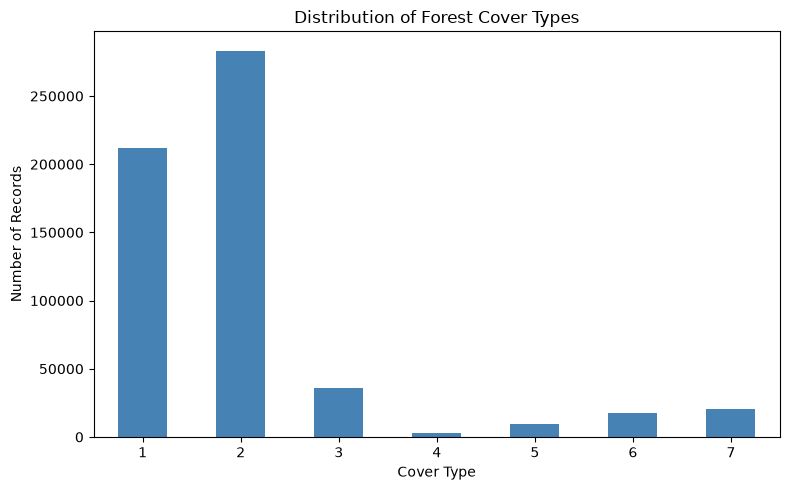

In [8]:
plt.figure(figsize=(8, 5))

df["Cover_Type"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue"
)

plt.title("Distribution of Forest Cover Types")
plt.xlabel("Cover Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
X = df.drop(columns=["Cover_Type"])
y = df["Cover_Type"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Number of classes:", y.nunique())

Feature shape: (581012, 54)
Target shape: (581012,)
Number of classes: 7


In [10]:
X_sample, _, y_sample, _ = train_test_split(
    X,
    y,
    train_size=min(5000, len(df)),
    random_state=42,
    stratify=y
)

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4000
Testing records: 1000


In [13]:
# Impute missing feature values
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Missing values handled.")
print("Feature scaling completed.")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Missing values handled.
Feature scaling completed.
Scaled training shape: (4000, 54)
Scaled testing shape: (1000, 54)


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Feature scaling completed.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed.
Training data shape: (4000, 54)
Testing data shape: (1000, 54)


In [15]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

models = {
    "Linear SVM": SVC(kernel="linear"),
    "Polynomial SVM": SVC(kernel="poly", degree=3),
    "RBF SVM": SVC(kernel="rbf")
}

results = {}
predictions = {}

for name, model in models.items():
    print("\nTraining", name)

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    predictions[name] = y_pred
    results[name] = accuracy_score(y_test, y_pred)

    print(f"Accuracy: {results[name] * 100:.2f}%")


Training Linear SVM
Accuracy: 73.40%

Training Polynomial SVM
Accuracy: 69.10%

Training RBF SVM
Accuracy: 74.40%


In [16]:
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


 Linear SVM
              precision    recall  f1-score   support

           1       0.71      0.73      0.72       365
           2       0.76      0.80      0.78       488
           3       0.67      0.84      0.74        61
           4       1.00      0.20      0.33         5
           5       0.00      0.00      0.00        16
           6       0.57      0.13      0.22        30
           7       0.75      0.51      0.61        35

    accuracy                           0.73      1000
   macro avg       0.64      0.46      0.49      1000
weighted avg       0.72      0.73      0.72      1000


 Polynomial SVM
              precision    recall  f1-score   support

           1       0.74      0.52      0.61       365
           2       0.68      0.87      0.76       488
           3       0.70      0.85      0.77        61
           4       0.75      0.60      0.67         5
           5       0.00      0.00      0.00        16
           6       0.40      0.13      0.20     

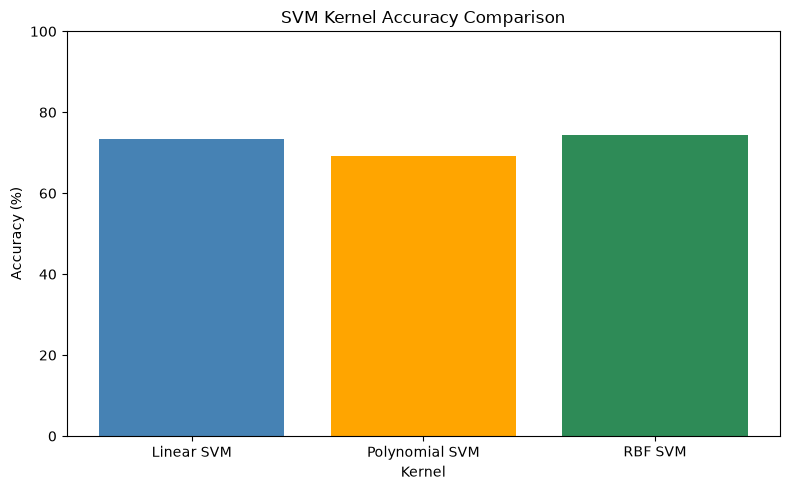

Final results:
Linear SVM: 73.40%
Polynomial SVM: 69.10%
RBF SVM: 74.40%


In [18]:
plt.figure(figsize=(8, 5))

plt.bar(
    results.keys(),
    [accuracy * 100 for accuracy in results.values()],
    color=["steelblue", "orange", "seagreen"]
)

plt.title("SVM Kernel Accuracy Comparison")
plt.xlabel("Kernel")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("Final results:")
for name, accuracy in results.items():
    print(f"{name}: {accuracy * 100:.2f}%")

In [20]:
from sklearn.decomposition import PCA
from sklearn.svm import SVC
import numpy as np
import matplotlib.pyplot as plt

# Reduce features to 2 dimensions
pca_vis = PCA(n_components=2)

X_train_2d = pca_vis.fit_transform(X_train_scaled)
X_test_2d = pca_vis.transform(X_test_scaled)

# Create grid for decision boundaries
x_min = X_train_2d[:, 0].min() - 1
x_max = X_train_2d[:, 0].max() + 1
y_min = X_train_2d[:, 1].min() - 1
y_max = X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

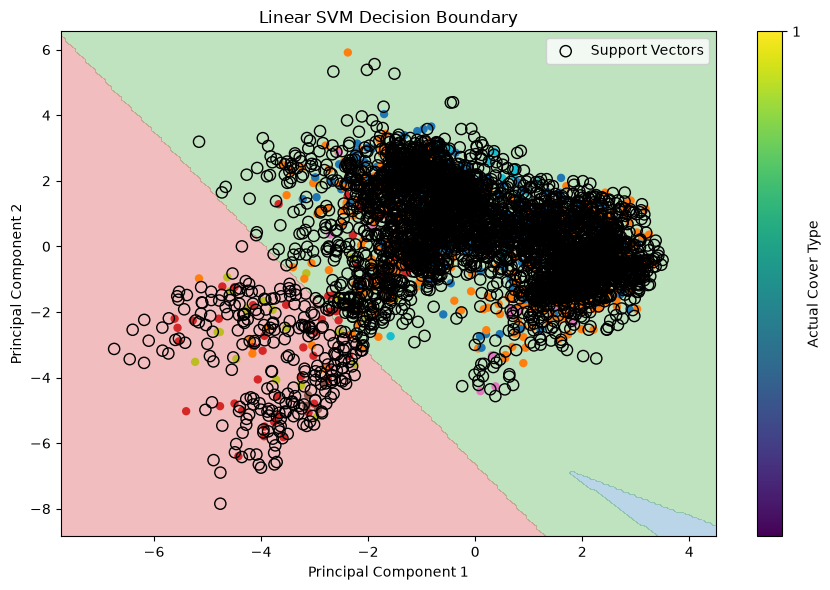

In [21]:
linear_svm = SVC(kernel="linear")
linear_svm.fit(X_train_2d, y_train)

Z_linear = linear_svm.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, Z_linear,
    levels=np.arange(0.5, 8.5, 1),
    cmap="tab10",
    alpha=0.3
)

plt.scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=y_test,
    cmap="tab10",
    vmin=1,
    vmax=7,
    s=25
)

plt.scatter(
    linear_svm.support_vectors_[:, 0],
    linear_svm.support_vectors_[:, 1],
    s=65,
    facecolors="none",
    edgecolors="black",
    label="Support Vectors"
)

plt.title("Linear SVM Decision Boundary")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(ticks=range(1, 8), label="Actual Cover Type")
plt.legend()
plt.tight_layout()
plt.show()

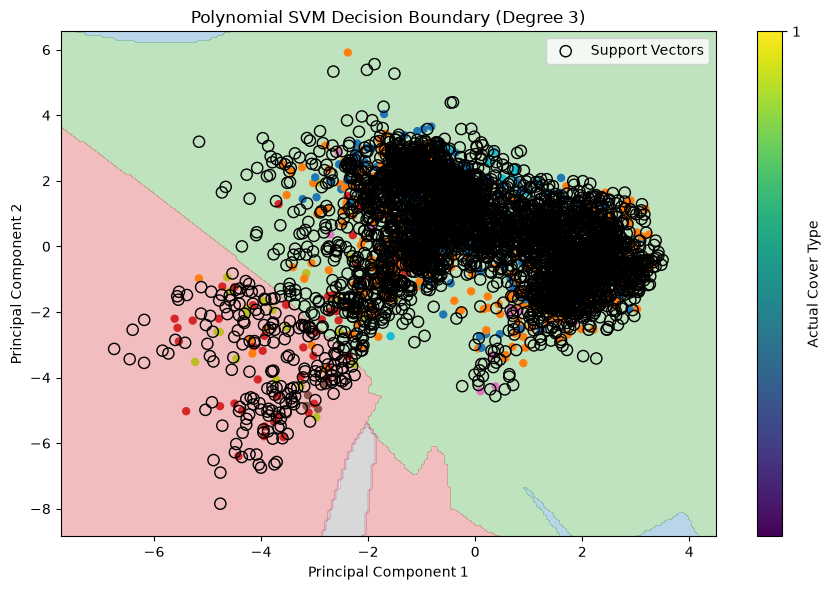

In [22]:
poly_svm = SVC(kernel="poly", degree=3)
poly_svm.fit(X_train_2d, y_train)

Z_poly = poly_svm.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, Z_poly,
    levels=np.arange(0.5, 8.5, 1),
    cmap="tab10",
    alpha=0.3
)

plt.scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=y_test,
    cmap="tab10",
    vmin=1,
    vmax=7,
    s=25
)

plt.scatter(
    poly_svm.support_vectors_[:, 0],
    poly_svm.support_vectors_[:, 1],
    s=65,
    facecolors="none",
    edgecolors="black",
    label="Support Vectors"
)

plt.title("Polynomial SVM Decision Boundary (Degree 3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(ticks=range(1, 8), label="Actual Cover Type")
plt.legend()
plt.tight_layout()
plt.show()

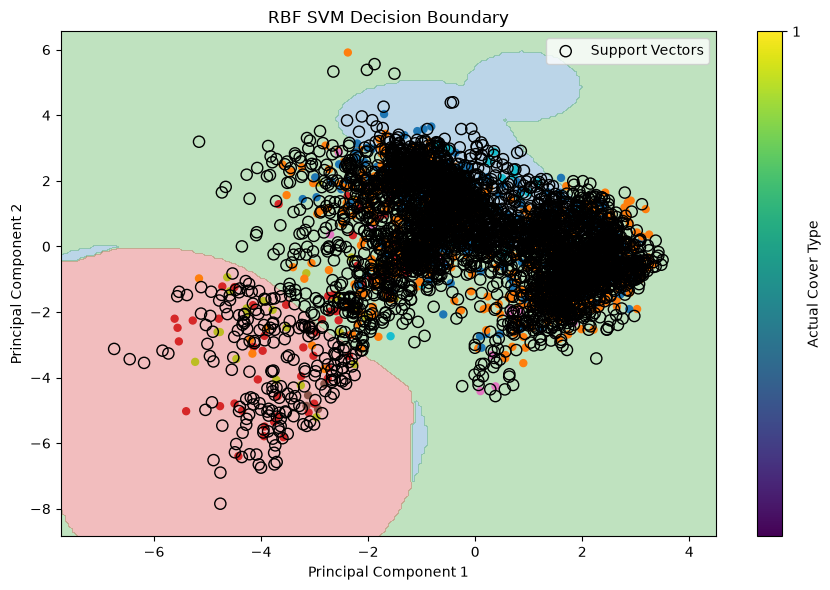

In [23]:
rbf_svm = SVC(kernel="rbf")
rbf_svm.fit(X_train_2d, y_train)

Z_rbf = rbf_svm.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, Z_rbf,
    levels=np.arange(0.5, 8.5, 1),
    cmap="tab10",
    alpha=0.3
)

plt.scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=y_test,
    cmap="tab10",
    vmin=1,
    vmax=7,
    s=25
)

plt.scatter(
    rbf_svm.support_vectors_[:, 0],
    rbf_svm.support_vectors_[:, 1],
    s=65,
    facecolors="none",
    edgecolors="black",
    label="Support Vectors"
)

plt.title("RBF SVM Decision Boundary")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(ticks=range(1, 8), label="Actual Cover Type")
plt.legend()
plt.tight_layout()
plt.show()